# Liberty Data Drive 2026 — Working File
**Status:** sections 1–5 (setup → candidate scan). Sections 6–12 are added after the topic is chosen.

Data: Fraser Institute *Economic Freedom of the World* (EFW Ratings sheet, sub-components) and UNDP HDR composite-indices time series (1990–2023).
Raw files are never edited. Every number below is computed from them.

## 1. Setup

In [1]:
import os, glob, sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

# Colab: upload data/EFW_original.xlsx and data/UNDP_original.csv (or edit URLs below)
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB and not os.path.exists("data/EFW_original.xlsx"):
    from google.colab import files
    os.makedirs("data", exist_ok=True)
    print("Upload EFW_original.xlsx and UNDP_original.csv"); up = files.upload()
    for k, v in up.items(): open(f"data/{k}", "wb").write(v)
EFW_PATH, UNDP_PATH = "data/EFW_original.xlsx", "data/UNDP_original.csv"
assert os.path.exists(EFW_PATH) and os.path.exists(UNDP_PATH), "data files missing"

## 2. Load data

In [2]:
efw = pd.read_excel(EFW_PATH, sheet_name="EFW Ratings", header=3)
efw.columns = [str(c).strip() for c in efw.columns]
efw = efw[pd.to_numeric(efw["Year"], errors="coerce").notna()].copy()
efw["Year"] = efw["Year"].astype(int)
print("EFW:", efw.shape, "| years:", efw.Year.min(), "-", efw.Year.max(), "| countries:", efw.ISO_Code.nunique())

undp_wide = pd.read_csv(UNDP_PATH, encoding="latin1")
VARS = {"gnipc": "GNI per capita (2021 PPP$)", "le": "Life expectancy (years)",
        "eys": "Expected years of schooling", "mys": "Mean years of schooling"}
rows = []
for v in VARS:
    cols = [c for c in undp_wide.columns if c.startswith(v + "_") and c.split("_")[1].isdigit()]
    m = undp_wide.melt(id_vars=["iso3", "country"], value_vars=cols, var_name="k", value_name=v)
    m["year"] = m.k.str.split("_").str[1].astype(int)
    rows.append(m.set_index(["iso3", "country", "year"])[v])
undp = pd.concat(rows, axis=1).reset_index()
print("UNDP:", undp.shape, "| years:", undp.year.min(), "-", undp.year.max(), "| countries:", undp.iso3.nunique())

EFW: (5115, 87) | years: 1970 - 2024 | countries: 165
UNDP: (7004, 7) | years: 1990 - 2023 | countries: 206


## 3. Inspect

In [3]:
print("EFW years available:", sorted(efw.Year.unique())[:8], "... annual from 2000")
sub = ["4Aii  Mean tariff rate", "4A  Tariffs", "4B  Regulatory trade barriers", "4C  Black market exchange rates",
       "2C  Property rights", "2F Contracts", "5Dii Business Permits", "Area 4 Freedom to trade internationally"]
sub = [c for c in sub if c in efw.columns]
print("Missing sub-components:", [c for c in ["4Aii  Mean tariff rate","4A  Tariffs","4B  Regulatory trade barriers","4C  Black market exchange rates","2C  Property rights","2F Contracts","5Dii Business Permits"] if c not in efw.columns])
cov = efw.groupby("Year")[sub].agg(lambda s: pd.to_numeric(s, errors="coerce").notna().sum())
print("Non-missing obs per year (selected sub-components):"); display(cov.loc[[1990,1995,2000,2005,2010,2015,2020]])
print("UNDP non-missing by variable:"); display(undp[list(VARS)].notna().sum())

EFW years available: [np.int64(1970), np.int64(1975), np.int64(1980), np.int64(1985), np.int64(1990), np.int64(1995), np.int64(2000), np.int64(2001)] ... annual from 2000
Missing sub-components: []
Non-missing obs per year (selected sub-components):


,4Aii Mean tariff rate,4A Tariffs,4B Regulatory trade barriers,4C Black market exchange rates,2C Property rights,2F Contracts,5Dii Business Permits,Area 4 Freedom to trade internationally
Year,,,,,,,,
1990,87,111,0,120,57,125,0,111
1995,99,116,0,123,80,141,0,116
2000,112,128,151,123,165,165,0,129
2005,141,141,158,141,165,165,135,141
2010,150,152,165,152,165,165,150,152
2015,158,158,165,158,165,165,157,159
2020,162,164,165,165,165,165,161,165


UNDP non-missing by variable:


gnipc    6852
le       7004
eys      6684
mys      6455
dtype: int64

## 4. Country matching (ISO3)

In [4]:
e_iso, u_iso = set(efw.ISO_Code.dropna()), set(undp.iso3.dropna())
print("EFW codes:", len(e_iso), "| UNDP codes:", len(u_iso), "| matched:", len(e_iso & u_iso))
print("In EFW, not in UNDP:", sorted(e_iso - u_iso))
print("(UNDP-only codes are mostly aggregates/regions, not needed.)")
SOUTH_ASIA = ["AFG","BGD","BTN","IND","MDV","NPL","PAK","LKA"]
print("South Asia in EFW:", sorted(set(SOUTH_ASIA) & e_iso), "| in UNDP:", sorted(set(SOUTH_ASIA) & u_iso))
NAME = efw.drop_duplicates("ISO_Code").set_index("ISO_Code")["Countries"]

EFW codes: 165 | UNDP codes: 206 | matched: 164
In EFW, not in UNDP: ['TWN']
(UNDP-only codes are mostly aggregates/regions, not needed.)
South Asia in EFW: ['BGD', 'BTN', 'IND', 'LKA', 'NPL', 'PAK'] | in UNDP: ['AFG', 'BGD', 'BTN', 'IND', 'LKA', 'MDV', 'NPL', 'PAK']


## 5. Candidate exploration
**Rule (applied identically to every indicator):** a country is a candidate case if its EFW sub-component score rose by **≥ 2.0 points** (0–10 scale) between **1995 and 2005**, both observations exist, and it has UNDP GNI per capita for 1990–2023.
Why 1995–2005? UNDP starts in 1990, so a reform needs ≥5 years of UNDP history before it and ≥10 after. EFW is 5-yearly before 2000, so the exact year is *not* read from EFW; it is dated later from public sources.
The threshold is a scan parameter, not a final selection. Final selection and reform dates come in section 6–7.

In [5]:
A, B, THRESH = 1995, 2005, 2.0
cands = ["4Aii  Mean tariff rate", "4A  Tariffs", "4B  Regulatory trade barriers", "4C  Black market exchange rates",
         "2C  Property rights", "2F Contracts", "5Dii Business Permits", "Area 4 Freedom to trade internationally",
         "Area 2 Legal System & Property Rights -- Without Gender Adjustment"]
cands = [c for c in cands if c in efw.columns]
num = efw.copy()
for c in cands: num[c] = pd.to_numeric(num[c], errors="coerce")
has_gni = set(undp.dropna(subset=["gnipc"]).iso3)
summ, detail = [], {}
for c in cands:
    p = num.pivot_table(index="ISO_Code", columns="Year", values=c)
    if A not in p or B not in p: continue
    d = (p[B] - p[A]).dropna()
    d = d[d.index.isin(has_gni)]
    hit = d[d >= THRESH].sort_values(ascending=False)
    neg = d[d <= -THRESH]
    detail[c] = hit
    summ.append({"indicator": c, "n_with_both_years": len(d), "n_rose_>=%.1f" % THRESH: len(hit),
                 "n_fell_>=%.1f" % THRESH: len(neg), "median_change": round(d.median(), 2),
                 "south_asia_hits": [i for i in hit.index if i in SOUTH_ASIA]})
scan = pd.DataFrame(summ).sort_values("n_rose_>=%.1f" % THRESH, ascending=False)
display(scan)

,indicator,n_with_both_years,n_rose_>=2.0,n_fell_>=2.0,median_change,south_asia_hits
3,2C Property rights,79,40,2,2.01,[]
0,4Aii Mean tariff rate,98,27,0,0.80,"[PAK, BGD, IND, LKA]"
1,4A Tariffs,115,22,5,0.10,"[PAK, IND, BGD, LKA]"
5,Area 4 Freedom to trade internationally,115,14,2,0.51,"[BGD, IND, LKA]"
2,4C Black market exchange rates,122,11,1,0.10,"[BGD, NPL]"
4,2F Contracts,140,1,30,-0.79,[]
6,Area 2 Legal System & Property Rights -- Witho...,164,1,4,-0.28,[]


In [6]:
# Peek at the top countries for each indicator (so cases are chosen by rule, not by eye)
for c, hit in detail.items():
    print(f"\n{c}: {len(hit)} countries rose >= {THRESH}")
    print(", ".join(f"{NAME.get(i,i)} ({v:+.1f})" for i, v in hit.head(12).items()))


4Aii  Mean tariff rate: 27 countries rose >= 2.0
Pakistan (+7.1), Bangladesh (+6.6), India (+6.6), China (+5.7), Mauritius (+5.5), Thailand (+5.1), Philippines (+4.4), Kenya (+4.4), Côte d'Ivoire (+4.1), Senegal (+4.0), Madagascar (+3.7), Rwanda (+3.5)

4A  Tariffs: 22 countries rose >= 2.0
Myanmar (+5.4), Rwanda (+5.2), Pakistan (+5.1), India (+4.7), Bangladesh (+4.3), China (+4.1), Senegal (+3.9), Belize (+3.6), Algeria (+3.2), Mauritius (+3.0), Albania (+2.5), Niger (+2.4)

4C  Black market exchange rates: 11 countries rose >= 2.0
Iran, Islamic Rep. (+10.0), Syrian Arab Republic (+10.0), Haiti (+9.4), Algeria (+7.9), Nigeria (+7.9), Bangladesh (+5.6), Nepal (+3.8), Burundi (+3.7), Venezuela, RB (+3.5), Paraguay (+2.6), Ecuador (+2.4)

2C  Property rights: 40 countries rose >= 2.0
Thailand (+5.0), Korea, Rep. (+4.4), Barbados (+4.4), Guatemala (+4.2), Iceland (+3.9), Estonia (+3.8), Lithuania (+3.8), Portugal (+3.6), Czechia (+3.5), Hong Kong SAR, China (+3.3), Latvia (+3.2), Chile 

## 6. Case selection (fixed rule)
**Rule:** every country whose **raw mean tariff rate (%)** fell by **≥ 20 percentage points between 1995 and 2005** (EFW Ratings, data column beside *4Aii Mean tariff rate*), with UNDP GNI per capita available.
The raw rate is used because the 0–10 score is floored at 0 for tariffs above ~50%, which hides most of the South Asian change.
No country is added or removed after seeing outcomes.

In [7]:
i = list(efw.columns).index("4Aii  Mean tariff rate")
efw["tariff_raw"] = pd.to_numeric(efw[efw.columns[i + 1]], errors="coerce")   # % mean tariff rate
tar = efw[["ISO_Code", "Year", "tariff_raw"]].dropna()
P = tar.pivot_table(index="ISO_Code", columns="Year", values="tariff_raw")
A, B, RULE_PP = 1995, 2005, 20.0
chg = (P[B] - P[A]).dropna()
chg = chg[chg.index.isin(has_gni)]
cases = chg[chg <= -RULE_PP].sort_values()
print(f"{len(cases)} cases (tariff fell >= {RULE_PP} pp, {A}->{B}); {len(chg)} countries had both years + GNI")
display(pd.DataFrame({"country": [NAME[c] for c in cases.index], f"tariff {A} (%)": P.loc[cases.index, A].round(1),
                      f"tariff {B} (%)": P.loc[cases.index, B].round(1), "change (pp)": cases.round(1)}))
near = chg[(chg <= -15) & (chg > -RULE_PP)].sort_values()
print("Just outside the rule (sensitivity only):", ", ".join(f"{NAME[c]} ({v:.1f})" for c, v in near.items()))

10 cases (tariff fell >= 20.0 pp, 1995->2005); 98 countries had both years + GNI


,country,tariff 1995 (%),tariff 2005 (%),change (pp)
ISO_Code,,,,
BGD,Bangladesh,81.2,16.8,-64.4
PAK,Pakistan,61.1,14.6,-46.5
IND,India,55.2,17.0,-38.2
CHN,China,37.5,9.2,-28.3
MUS,Mauritius,36.2,8.5,-27.7
THA,Thailand,36.0,10.6,-25.4
PHL,Philippines,27.6,5.4,-22.2
KEN,Kenya,34.0,12.1,-21.9
CIV,Côte d'Ivoire,33.0,12.6,-20.4


Just outside the rule (sensitivity only): Madagascar (-18.4), Rwanda (-17.6), Malawi (-17.3), Burundi (-17.3), Poland (-15.7)


## 7. Reform dates
`reform_year` = first year the government's main tariff cut took legal effect, confirmed in an open document (same logic for every country).
Rows marked **UNVERIFIED** are leads only and must be confirmed before the deck is final. Full log: `research/policy_notes.md`.
Côte d'Ivoire and Senegal share one WAEMU reform, so they are **not independent** — flagged and tested in section 10.

In [8]:
DATES_CSV = """iso3,country,reform_year,reform_description,effective_date,source_url,accessed,status
IND,India,1991,"Union Budget 1991-92: ad valorem customs peak capped at 150% (previously >300% on some lines)",July 1991 (budget day),https://www.indiabudget.gov.in/doc/bspeech/bs199192.pdf,2026-10-13,VERIFIED (primary source read)
BGD,Bangladesh,1995,"LEAD ONLY: FY1994/95 tariff restructuring (max rate cut sharply; fewer bands)",FY1994/95,,,UNVERIFIED
PAK,Pakistan,1997,"LEAD ONLY: 1997-98 budget tariff rationalisation; further cuts 2001-02",FY1997/98,,,UNVERIFIED
CHN,China,1992,"LEAD ONLY: tariff cuts from 1992 ahead of WTO accession (2001)",1992,,,UNVERIFIED
MUS,Mauritius,1999,"LEAD ONLY: tariff reform of late 1990s / 2000s",?,,,UNVERIFIED
THA,Thailand,1995,"LEAD ONLY: tariff structure reductions mid-1990s",?,,,UNVERIFIED
PHL,Philippines,1995,"Executive Order 264 (signed 22 Jul 1995; industrial tariff reduction programme in effect from 28 Aug 1995 per EO 288 recital)",28 Aug 1995,https://lawphil.net/executive/execord/eo1995/eo_264_1995.html; https://lawphil.net/executive/execord/eo1995/eo_288_1995.html,2026-10-13,VERIFIED (primary source read)
KEN,Kenya,1993,"LEAD ONLY: early-1990s import liberalisation",?,,,UNVERIFIED
CIV,Cote d'Ivoire,2000,"LEAD ONLY: WAEMU common external tariff",Jan 2000,,,UNVERIFIED
SEN,Senegal,2000,"LEAD ONLY: WAEMU common external tariff (same reform as CIV)",Jan 2000,,,UNVERIFIED
"""
from io import StringIO
dates = pd.read_csv(StringIO(DATES_CSV))
miss = set(cases.index) ^ set(dates.iso3)
assert not miss, f"cases vs reform-date table mismatch: {miss}"
display(dates[["iso3", "country", "reform_year", "effective_date", "status"]])
n_unv = dates.status.str.startswith("UNVERIFIED").sum()
print(f"WARNING: {n_unv} of {len(dates)} reform dates are still UNVERIFIED leads." if n_unv else "All reform dates verified.")

,iso3,country,reform_year,effective_date,status
0,IND,India,1991,July 1991 (budget day),VERIFIED (primary source read)
1,BGD,Bangladesh,1995,FY1994/95,UNVERIFIED
2,PAK,Pakistan,1997,FY1997/98,UNVERIFIED
3,CHN,China,1992,1992,UNVERIFIED
4,MUS,Mauritius,1999,?,UNVERIFIED
5,THA,Thailand,1995,?,UNVERIFIED
6,PHL,Philippines,1995,28 Aug 1995,VERIFIED (primary source read)
7,KEN,Kenya,1993,?,UNVERIFIED
8,CIV,Cote d'Ivoire,2000,Jan 2000,UNVERIFIED
9,SEN,Senegal,2000,Jan 2000,UNVERIFIED


## 8. Event-time dataset
`event_time = year − reform_year` (0 = reform year). Window: −5 … +10 years, clipped to UNDP coverage (1990–2023). Nothing is interpolated.
The EFW tariff series is 5-yearly before 2000, so some event years have no EFW value (left blank).

In [9]:
LO, HI = -5, 10
u = undp[undp.iso3.isin(cases.index)][["iso3", "year", "gnipc", "le", "eys", "mys"]].copy()
u = u.merge(dates[["iso3", "reform_year"]], on="iso3")
u["event_time"] = u.year - u.reform_year
panel = u[(u.event_time >= LO) & (u.event_time <= HI)].merge(
    tar.rename(columns={"ISO_Code": "iso3", "Year": "year"}), on=["iso3", "year"], how="left")
panel["country"] = panel.iso3.map(NAME)
panel = panel[["country", "iso3", "year", "reform_year", "event_time", "tariff_raw", "gnipc", "le", "eys", "mys"]]
print(panel.shape); display(panel.groupby("country").agg(first=("event_time", "min"), last=("event_time", "max"),
      n_gni=("gnipc", "count"), n_tariff=("tariff_raw", "count")))
base = panel[panel.event_time == 0].set_index("iso3")
panel["gni_index"] = panel.gnipc / panel.iso3.map(base.gnipc) * 100
panel["le_gain"] = panel["le"] - panel.iso3.map(base["le"])

(151, 10)


,first,last,n_gni,n_tariff
country,,,,
Bangladesh,-5,10,16,8
China,-2,10,13,5
Côte d'Ivoire,-5,10,16,12
India,-1,10,12,4
Kenya,-3,10,14,6
Mauritius,-5,10,16,11
Pakistan,-5,10,16,9
Philippines,-5,10,16,8
Senegal,-5,10,16,12


## 9. Main analysis (descriptive)
- **Growth:** average annual GNI per capita growth (CAGR) in the 5 years before vs the 10 years after the reform year. If fewer than 3 pre-years exist in UNDP data (1990 start), pre-growth is not computed (`NaN`).
- **Benchmark:** median CAGR of all *non-case* EFW countries over the **same calendar years** — a crude control for global conditions. Not a causal control.

In [10]:
def cagr(s, y0, y1):
    if y0 in s.index and y1 in s.index and s[y0] > 0 and s[y1] > 0:
        return (s[y1] / s[y0]) ** (1 / (y1 - y0)) - 1
    return np.nan
G = undp[undp.iso3.isin(e_iso)].pivot_table(index="iso3", columns="year", values="gnipc")
non_case = G.index.difference(cases.index)
def bench(y0, y1):
    return np.nanmedian([cagr(G.loc[c], y0, y1) for c in non_case])
rows = []
for iso, ry in dates.set_index("iso3").reform_year.items():
    s = G.loc[iso]; p0 = max(1990, ry - 5)
    pre = cagr(s, p0, ry) if ry - p0 >= 3 else np.nan
    post = cagr(s, ry, ry + 10)
    bpost = bench(ry, ry + 10)
    rows.append({"iso3": iso, "country": NAME[iso], "reform_year": ry, "pre_years_available": ry - p0,
                 "pre_cagr_%": pre * 100, "post_cagr_%": post * 100, "benchmark_post_%": bpost * 100,
                 "excess_vs_bench_pp": (post - bpost) * 100})
res = pd.DataFrame(rows).sort_values("excess_vs_bench_pp", ascending=False).reset_index(drop=True)
display(res.round(2))
print("Cases with post growth above benchmark:", (res.excess_vs_bench_pp > 0).sum(), "of", len(res))
print("Median post-reform CAGR: %.2f%% | median benchmark: %.2f%%" % (res["post_cagr_%"].median(), res["benchmark_post_%"].median()))

,iso3,country,reform_year,pre_years_available,pre_cagr_%,post_cagr_%,benchmark_post_%,excess_vs_bench_pp
0,CHN,China,1992,2,NaN,8.71,1.74,6.97
1,IND,India,1991,1,NaN,3.97,1.70,2.27
2,MUS,Mauritius,1999,5,3.78,3.85,2.33,1.53
3,BGD,Bangladesh,1995,5,2.57,3.79,2.36,1.43
4,PHL,Philippines,1995,5,1.52,2.76,2.36,0.39
5,PAK,Pakistan,1997,5,0.11,2.33,2.60,-0.27
6,THA,Thailand,1995,5,6.73,1.65,2.36,-0.71
7,SEN,Senegal,2000,5,1.97,0.82,2.48,-1.66
8,KEN,Kenya,1993,3,-3.45,0.10,1.88,-1.78
9,CIV,Côte d'Ivoire,2000,5,0.29,-0.48,2.48,-2.96


Cases with post growth above benchmark: 5 of 10
Median post-reform CAGR: 2.54% | median benchmark: 2.36%


## 10. Counterexamples and robustness
(a) The case(s) that do **not** beat the benchmark are charted, not hidden. (b) Dependence on the two WAEMU cases (CIV, SEN). (c) Sensitivity to the selection threshold (adding the borderline cases).

In [11]:
lag = res[res.excess_vs_bench_pp <= 0]
print("Cases at or below benchmark:", list(lag.country) or "none")
nw = res[~res.iso3.isin(["CIV", "SEN"])]
print("Excluding CIV & SEN (one shared reform): %d/%d beat benchmark; median excess %.2f pp"
      % ((nw.excess_vs_bench_pp > 0).sum(), len(nw), nw.excess_vs_bench_pp.median()))
print("All cases: median excess %.2f pp" % res.excess_vs_bench_pp.median())
print("Note: borderline countries (-15 to -20 pp) listed in section 6 are not in the main sample.")

Cases at or below benchmark: ['Pakistan', 'Thailand', 'Senegal', 'Kenya', "Côte d'Ivoire"]
Excluding CIV & SEN (one shared reform): 5/8 beat benchmark; median excess 0.91 pp
All cases: median excess 0.06 pp
Note: borderline countries (-15 to -20 pp) listed in section 6 are not in the main sample.


## 11. Final figures
Each figure is one cell; `register()` records it for the chart index.

In [12]:
import matplotlib as mpl
os.makedirs("figures", exist_ok=True)
mpl.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": .25, "font.size": 10})
SRC = "Sources: Fraser Institute EFW (Ratings sheet); UNDP HDR 2025 composite-indices time series."
CHART_INDEX = []
def register(fig_id, slide, what, cell):
    CHART_INDEX.append({"Fig": fig_id, "Slide": slide, "What it shows": what, "Location in working file": f"Notebook cell {cell} -> figures/{fig_id}.png"})
def finish(fig, fig_id, title, note):
    fig.suptitle(title, fontsize=12, fontweight="bold", x=0.01, ha="left")
    fig.text(0.01, 0.005, note + "\n" + SRC, fontsize=7.5, color="#444", va="bottom")
    fig.tight_layout(rect=[0, 0.07, 1, 0.95]); fig.savefig(f"figures/{fig_id}.png", dpi=200); plt.show()
order = list(res.iso3)

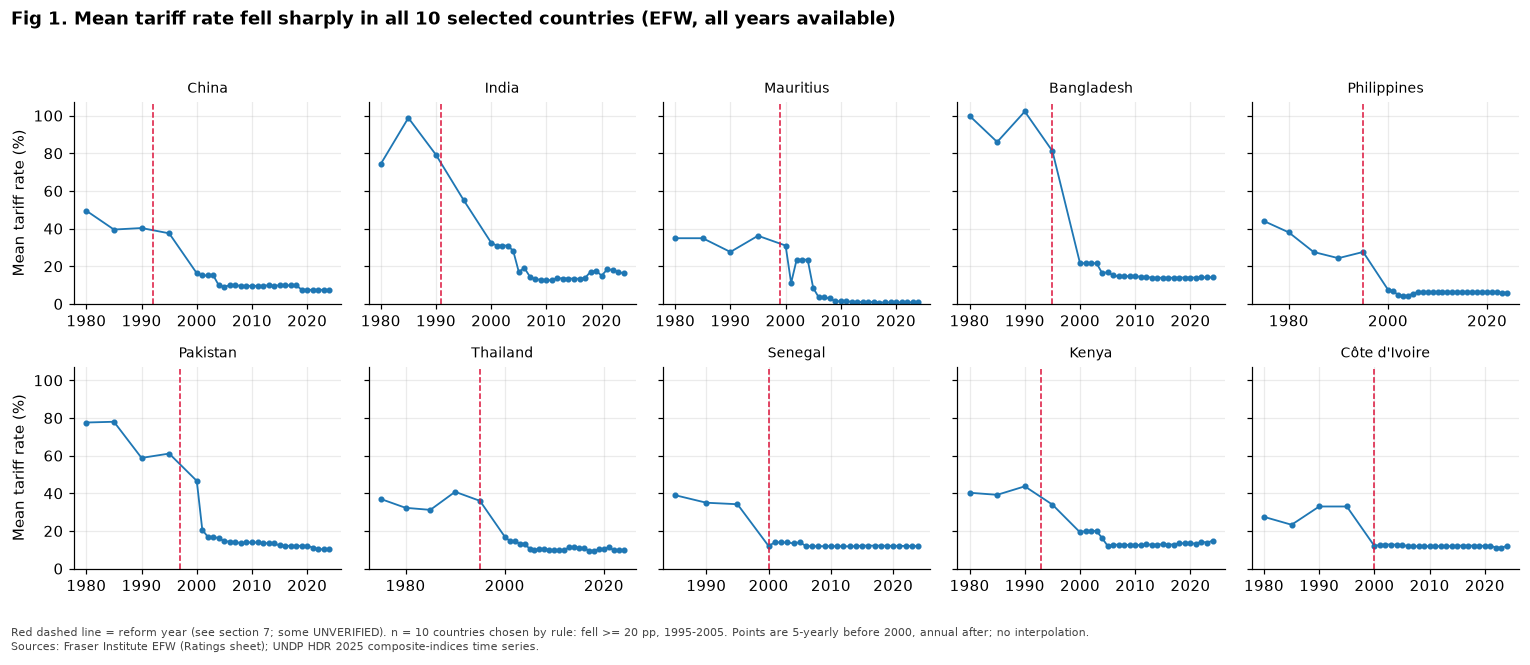

In [13]:
# Fig1: tariff trajectories (calendar years, markers = actual EFW observations)
fig, axes = plt.subplots(2, 5, figsize=(14, 6), sharey=True)
for ax, iso in zip(axes.flat, order):
    d = tar[tar.ISO_Code == iso].sort_values("Year"); d = d[d.Year <= 2024]
    ax.plot(d.Year, d.tariff_raw, "o-", ms=3, lw=1.2)
    ry = int(dates.set_index("iso3").loc[iso, "reform_year"]); ax.axvline(ry, color="crimson", ls="--", lw=1)
    ax.set_title(NAME[iso], fontsize=9)
ax.set_ylim(0, tar[tar.ISO_Code.isin(order) & (tar.Year <= 2024)].tariff_raw.max() * 1.05)   # full range, nothing clipped
for ax in axes[:, 0]: ax.set_ylabel("Mean tariff rate (%)")
finish(fig, "Fig1", "Fig 1. Mean tariff rate fell sharply in all 10 selected countries (EFW, all years available)",
       f"Red dashed line = reform year (see section 7; some UNVERIFIED). n = {len(order)} countries chosen by rule: fell >= {RULE_PP:.0f} pp, {A}-{B}. Points are 5-yearly before 2000, annual after; no interpolation.")
register("Fig1", 3, "Raw mean tariff rate, 10 selected countries, with reform year", 25)

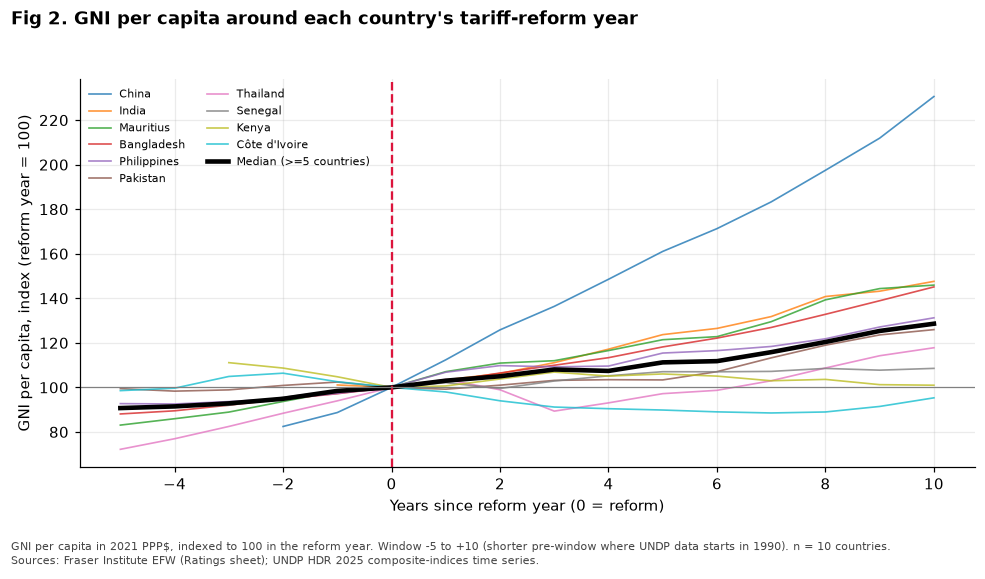

In [14]:
# Fig2: GNI per capita indexed to reform year = 100
fig, ax = plt.subplots(figsize=(9, 5.2))
for iso in order:
    d = panel[panel.iso3 == iso].sort_values("event_time")
    ax.plot(d.event_time, d.gni_index, lw=1.1, alpha=.8, label=NAME[iso])
med = panel.groupby("event_time").gni_index.median()
cnt = panel.groupby("event_time").gni_index.count()
med = med[cnt >= 5]
ax.plot(med.index, med.values, "k-", lw=3, label="Median (>=5 countries)")
ax.axvline(0, color="crimson", ls="--"); ax.axhline(100, color="grey", lw=.8)
ax.set_xlabel("Years since reform year (0 = reform)"); ax.set_ylabel("GNI per capita, index (reform year = 100)")
ax.legend(fontsize=7, ncol=2, frameon=False)
finish(fig, "Fig2", "Fig 2. GNI per capita around each country's tariff-reform year",
       f"GNI per capita in 2021 PPP$, indexed to 100 in the reform year. Window -5 to +10 (shorter pre-window where UNDP data starts in 1990). n = {len(order)} countries.")
register("Fig2", 5, "GNI per capita index aligned on reform year, 10 cases + median", 26)

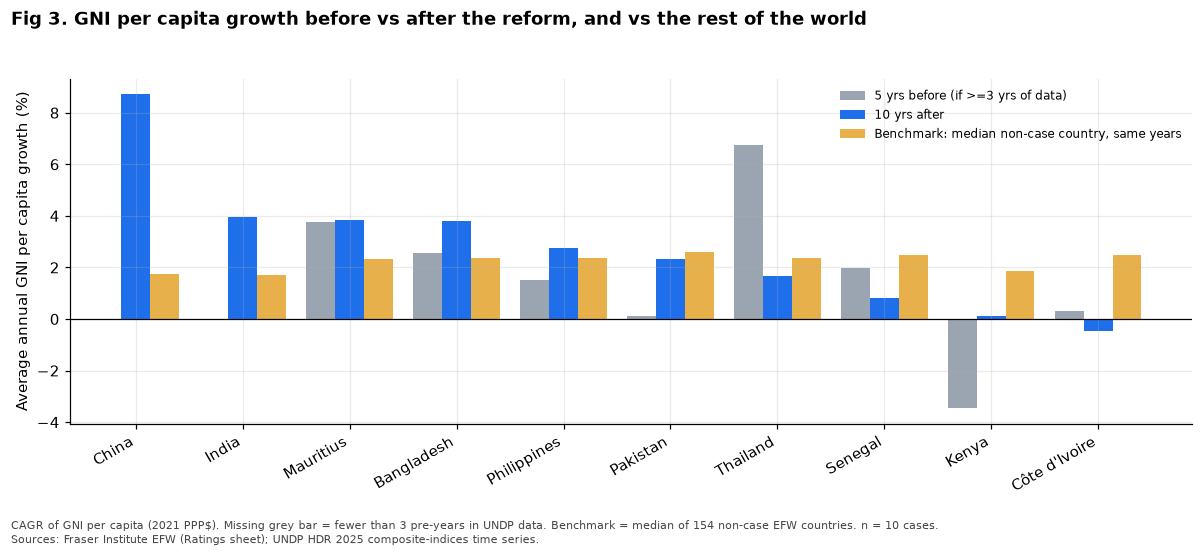

In [15]:
# Fig3: growth before vs after + benchmark (bars start at zero)
r = res.set_index("country")
x = np.arange(len(r)); w = .27
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(x - w, r["pre_cagr_%"], w, label="5 yrs before (if >=3 yrs of data)", color="#9aa5b1")
ax.bar(x, r["post_cagr_%"], w, label="10 yrs after", color="#1f6feb")
ax.bar(x + w, r["benchmark_post_%"], w, label="Benchmark: median non-case country, same years", color="#e8b04a")
ax.axhline(0, color="k", lw=.8); ax.set_xticks(x); ax.set_xticklabels(r.index, rotation=30, ha="right")
ax.set_ylabel("Average annual GNI per capita growth (%)"); ax.legend(frameon=False, fontsize=8)
finish(fig, "Fig3", "Fig 3. GNI per capita growth before vs after the reform, and vs the rest of the world",
       f"CAGR of GNI per capita (2021 PPP$). Missing grey bar = fewer than 3 pre-years in UNDP data. Benchmark = median of {len(non_case)} non-case EFW countries. n = {len(r)} cases.")
register("Fig3", 6, "Pre vs post GNI per capita CAGR and benchmark, by country", 27)

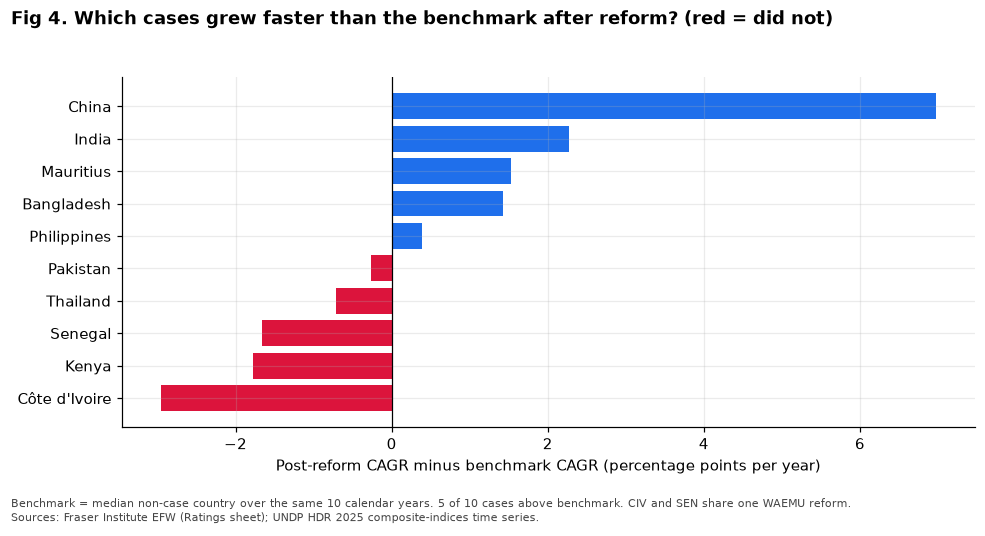

In [16]:
# Fig4: excess growth over benchmark (sorted) - shows who does NOT fit
fig, ax = plt.subplots(figsize=(9, 4.8))
colors = ["#1f6feb" if v > 0 else "crimson" for v in res.excess_vs_bench_pp]
ax.barh(res.country[::-1], res.excess_vs_bench_pp[::-1], color=colors[::-1])
ax.axvline(0, color="k", lw=.8); ax.set_xlabel("Post-reform CAGR minus benchmark CAGR (percentage points per year)")
finish(fig, "Fig4", "Fig 4. Which cases grew faster than the benchmark after reform? (red = did not)",
       f"Benchmark = median non-case country over the same 10 calendar years. {int((res.excess_vs_bench_pp>0).sum())} of {len(res)} cases above benchmark. CIV and SEN share one WAEMU reform.")
register("Fig4", 7, "Excess GNI growth over benchmark, counterexamples in red", 28)

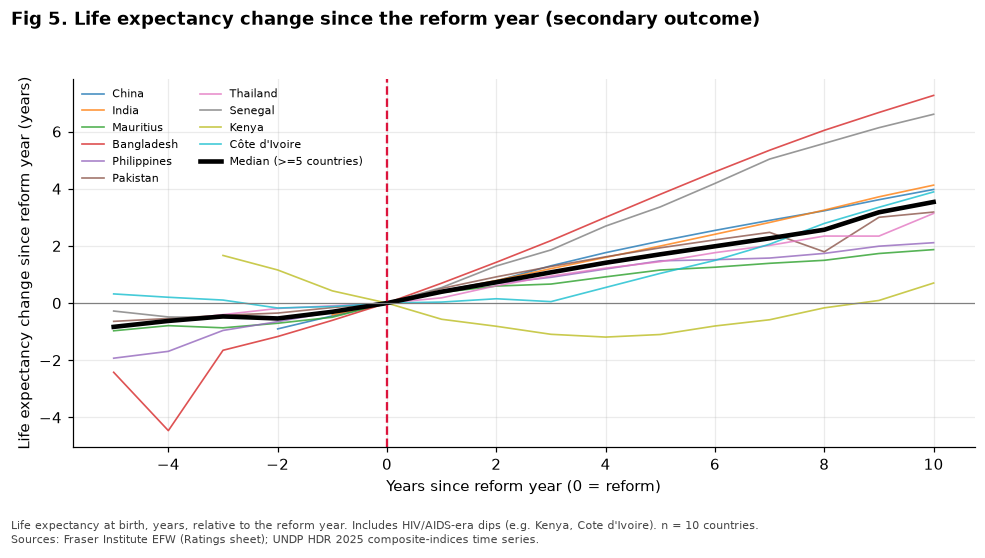

In [17]:
# Fig5: life expectancy gain since reform year (secondary outcome)
fig, ax = plt.subplots(figsize=(9, 5))
for iso in order:
    d = panel[panel.iso3 == iso].sort_values("event_time")
    ax.plot(d.event_time, d.le_gain, lw=1.1, alpha=.8, label=NAME[iso])
m = panel.groupby("event_time").le_gain.median(); m = m[panel.groupby("event_time").le_gain.count() >= 5]
ax.plot(m.index, m.values, "k-", lw=3, label="Median (>=5 countries)")
ax.axvline(0, color="crimson", ls="--"); ax.axhline(0, color="grey", lw=.8)
ax.set_xlabel("Years since reform year (0 = reform)"); ax.set_ylabel("Life expectancy change since reform year (years)")
ax.legend(fontsize=7, ncol=2, frameon=False)
finish(fig, "Fig5", "Fig 5. Life expectancy change since the reform year (secondary outcome)",
       f"Life expectancy at birth, years, relative to the reform year. Includes HIV/AIDS-era dips (e.g. Kenya, Cote d'Ivoire). n = {len(order)} countries.")
register("Fig5", 6, "Life expectancy gain aligned on reform year", 29)

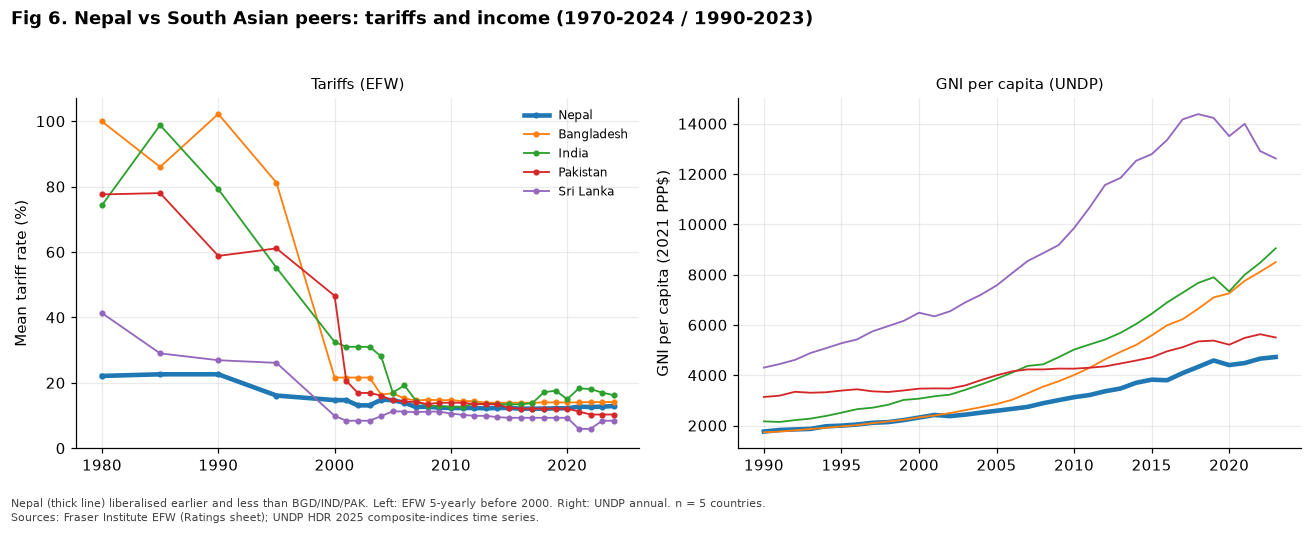

In [18]:
# Fig6: Nepal vs South Asian cases - tariff and GNI side by side (no dual axis)
SA = ["NPL", "BGD", "IND", "PAK", "LKA"]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.8))
for iso in SA:
    d = tar[(tar.ISO_Code == iso)].sort_values("Year"); lw = 3 if iso == "NPL" else 1.2
    a1.plot(d.Year, d.tariff_raw, "o-", ms=3, lw=lw, label=NAME[iso])
    g = undp[undp.iso3 == iso].sort_values("year"); a2.plot(g.year, g.gnipc, lw=lw, label=NAME[iso])
a1.set_ylabel("Mean tariff rate (%)"); a1.set_ylim(bottom=0); a1.set_title("Tariffs (EFW)", fontsize=10)
a2.set_ylabel("GNI per capita (2021 PPP$)"); a2.set_title("GNI per capita (UNDP)", fontsize=10); a1.legend(frameon=False, fontsize=8)
finish(fig, "Fig6", "Fig 6. Nepal vs South Asian peers: tariffs and income (1970-2024 / 1990-2023)",
       "Nepal (thick line) liberalised earlier and less than BGD/IND/PAK. Left: EFW 5-yearly before 2000. Right: UNDP annual. n = 5 countries.")
register("Fig6", 9, "Nepal vs South Asian peers: tariff and GNI per capita", 30)

## 12. Chart index and final checks

In [19]:
ci = pd.DataFrame(CHART_INDEX); display(ci); ci.to_csv("figures/chart_index.csv", index=False)
for f in ci.Fig: assert os.path.exists(f"figures/{f}.png"), f
assert panel.groupby("iso3").size().min() > 0
print("Checks passed. UNVERIFIED reform dates remaining:", int(dates.status.str.startswith("UNVERIFIED").sum()))

,Fig,Slide,What it shows,Location in working file
0,Fig1,3,"Raw mean tariff rate, 10 selected countries, w...",Notebook cell 25 -> figures/Fig1.png
1,Fig2,5,"GNI per capita index aligned on reform year, 1...",Notebook cell 26 -> figures/Fig2.png
2,Fig3,6,"Pre vs post GNI per capita CAGR and benchmark,...",Notebook cell 27 -> figures/Fig3.png
3,Fig4,7,"Excess GNI growth over benchmark, counterexamp...",Notebook cell 28 -> figures/Fig4.png
4,Fig5,6,Life expectancy gain aligned on reform year,Notebook cell 29 -> figures/Fig5.png
5,Fig6,9,Nepal vs South Asian peers: tariff and GNI per...,Notebook cell 30 -> figures/Fig6.png


Checks passed. UNVERIFIED reform dates remaining: 8
